In [44]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("vgsales.csv")

df.head(5)

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37


In [45]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16598 entries, 0 to 16597
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Rank          16598 non-null  int64  
 1   Name          16598 non-null  object 
 2   Platform      16598 non-null  object 
 3   Year          16327 non-null  float64
 4   Genre         16598 non-null  object 
 5   Publisher     16540 non-null  object 
 6   NA_Sales      16598 non-null  float64
 7   EU_Sales      16598 non-null  float64
 8   JP_Sales      16598 non-null  float64
 9   Other_Sales   16598 non-null  float64
 10  Global_Sales  16598 non-null  float64
dtypes: float64(6), int64(1), object(4)
memory usage: 1.4+ MB
None


In [46]:
df.isnull().sum()

Rank              0
Name              0
Platform          0
Year            271
Genre             0
Publisher        58
NA_Sales          0
EU_Sales          0
JP_Sales          0
Other_Sales       0
Global_Sales      0
dtype: int64

In [47]:
# заполним пропуски в полонке Publisher (None (Null) заменим на Unknown)
df['Publisher'].fillna("Unknown", inplace=True)
# удалим записи без года выпуска в колонке Year и преорбазуем к типу int
df.dropna(subset=['Year'], inplace=True)
df['Year'] = df['Year'].astype(int)

In [48]:
df.isnull().sum()

Rank            0
Name            0
Platform        0
Year            0
Genre           0
Publisher       0
NA_Sales        0
EU_Sales        0
JP_Sales        0
Other_Sales     0
Global_Sales    0
dtype: int64

In [49]:
# Проверка на дубли записей
print("Проверка на дублирурующиеся строки", df.duplicated().sum())

Проверка на дублирурующиеся строки 0


In [50]:
# посчитаем количество выпущенных игр по каждому жанру
genre_counts = df['Genre'].value_counts()

In [51]:
genre_counts

Genre
Action          3253
Sports          2304
Misc            1710
Role-Playing    1471
Shooter         1282
Adventure       1276
Racing          1226
Platform         876
Simulation       851
Fighting         836
Strategy         671
Puzzle           571
Name: count, dtype: int64

/tmp/ipykernel_173/171390003.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=genre_counts.index, y=genre_counts.values, palette='viridis')


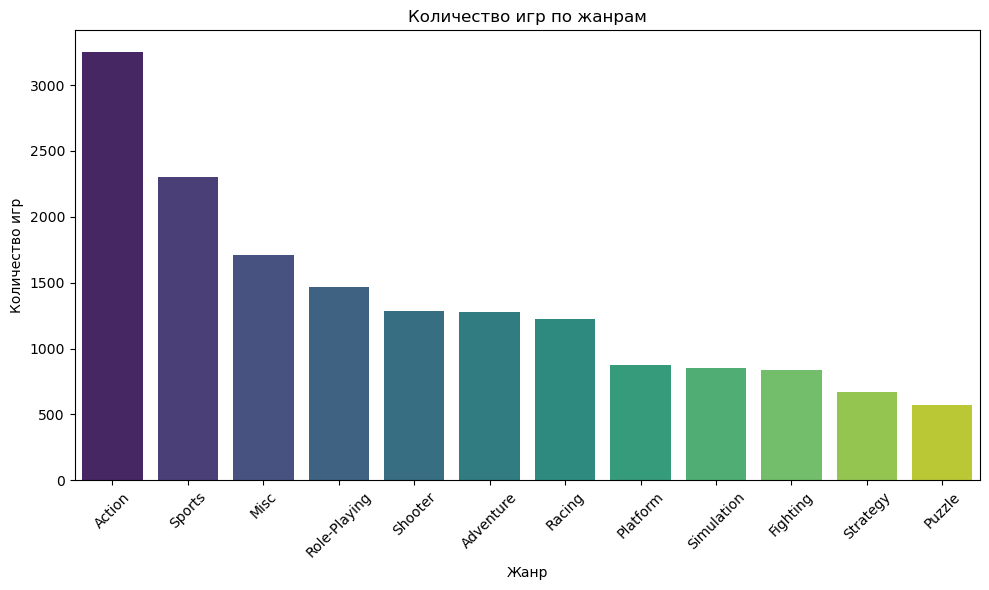

In [52]:
# построим столбчатую диаграмму (bar) количество игр по жанрам
import seaborn as sns
plt.figure(figsize=(10, 6))
sns.barplot(x=genre_counts.index, y=genre_counts.values, palette='viridis')
plt.title("Количество игр по жанрам")
plt.xlabel("Жанр")
plt.ylabel("Количество игр")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [53]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
Index: 16327 entries, 0 to 16597
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Rank          16327 non-null  int64  
 1   Name          16327 non-null  object 
 2   Platform      16327 non-null  object 
 3   Year          16327 non-null  int64  
 4   Genre         16327 non-null  object 
 5   Publisher     16327 non-null  object 
 6   NA_Sales      16327 non-null  float64
 7   EU_Sales      16327 non-null  float64
 8   JP_Sales      16327 non-null  float64
 9   Other_Sales   16327 non-null  float64
 10  Global_Sales  16327 non-null  float64
dtypes: float64(5), int64(2), object(4)
memory usage: 1.5+ MB
None


In [54]:
# Global_Sales Platform
# просуммируем глобальные продажи по каждой платформе
platform_sales= df.groupby('Platform')['Global_Sales'].sum().sort_values(ascending=False)
platform_sales

Platform
PS2     1233.46
X360     969.61
PS3      949.35
Wii      909.81
DS       818.96
PS       727.39
GBA      313.56
PSP      291.71
PS4      278.10
PC       255.05
GB       254.42
XB       252.09
NES      251.07
3DS      246.28
N64      218.21
SNES     200.05
GC       197.14
XOne     141.06
2600      86.57
WiiU      81.86
PSV       61.63
SAT       33.59
GEN       28.36
DC        15.97
SCD        1.87
NG         1.44
WS         1.42
TG16       0.16
3DO        0.10
GG         0.04
PCFX       0.03
Name: Global_Sales, dtype: float64

In [55]:
# возьмем топ 10 пллатформ а остальные объединим (Other). 11 секторов
# platform_sales index values 
labels = list(platform_sales.index[:10]) + ['other']
labels

['PS2', 'X360', 'PS3', 'Wii', 'DS', 'PS', 'GBA', 'PSP', 'PS4', 'PC', 'other']

In [56]:
sizes = list(platform_sales.values[:10]) + [platform_sales.values[10:].sum()]
sizes

[1233.46,
 969.61,
 949.35,
 909.81,
 818.96,
 727.39,
 313.56,
 291.71,
 278.1,
 255.05,
 2073.36]

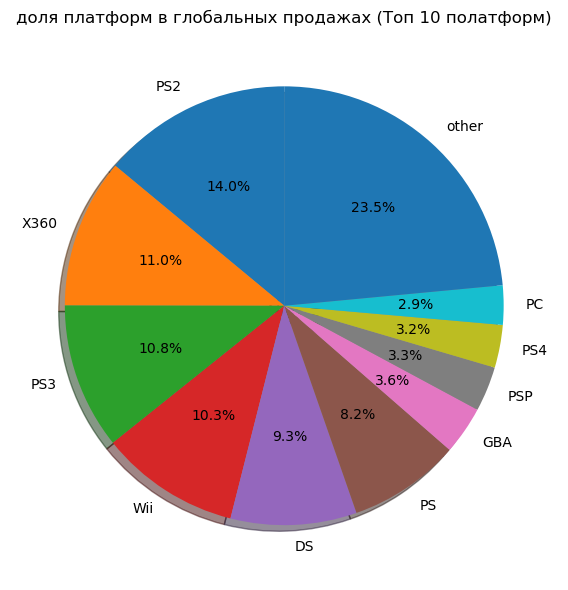

In [57]:
# построим круговую диаграмму - доля платформ в глобальных продажах (Топ 10 полатформ) 11 сегмeнтов
# pie
plt.figure(figsize=(10, 6))
plt.pie(sizes, labels=labels, autopct='%1.1f%%',  startangle=90, shadow=True)
plt.title('доля платформ в глобальных продажах (Топ 10 полатформ)')

plt.tight_layout()
plt.show()

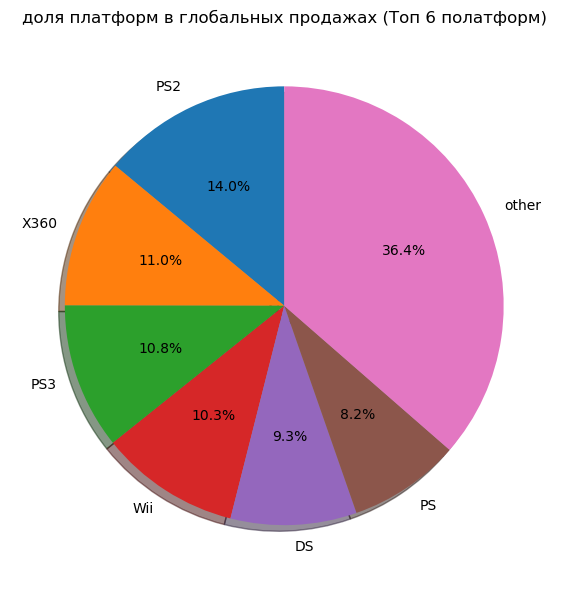

In [58]:
# построим круговую диаграмму - доля платформ в глобальных продажах (Топ 6 полатформ) 7 сегмeнтов
platform_sales= df.groupby('Platform')['Global_Sales'].sum().sort_values(ascending=False)
labels = list(platform_sales.index[:6]) + ['other']
sizes = list(platform_sales.values[:6]) + [platform_sales.values[6:].sum()]
plt.figure(figsize=(10, 6))
plt.pie(sizes, labels=labels, autopct='%1.1f%%',  startangle=90, shadow=True)
plt.title('доля платформ в глобальных продажах (Топ 6 полатформ)')


plt.tight_layout()
plt.show()

In [59]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
Index: 16327 entries, 0 to 16597
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Rank          16327 non-null  int64  
 1   Name          16327 non-null  object 
 2   Platform      16327 non-null  object 
 3   Year          16327 non-null  int64  
 4   Genre         16327 non-null  object 
 5   Publisher     16327 non-null  object 
 6   NA_Sales      16327 non-null  float64
 7   EU_Sales      16327 non-null  float64
 8   JP_Sales      16327 non-null  float64
 9   Other_Sales   16327 non-null  float64
 10  Global_Sales  16327 non-null  float64
dtypes: float64(5), int64(2), object(4)
memory usage: 1.5+ MB
None


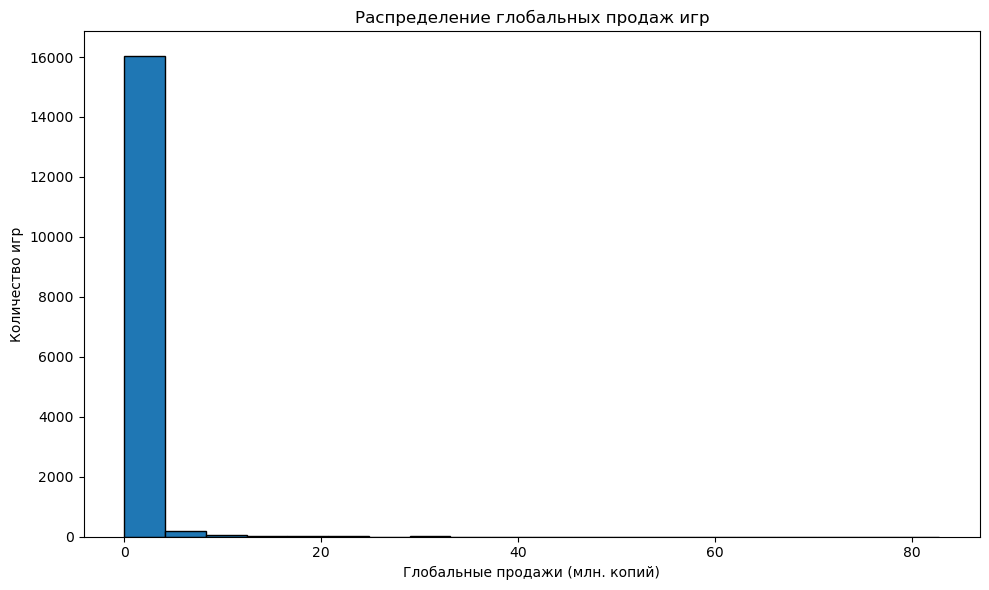

In [60]:
# Global_Sales 
# построим гистограмму распределления глобальных продаж игр
# hist

plt.figure(figsize=(10, 6))
plt.hist(df['Global_Sales'], bins=20, edgecolor='black')
plt.title("Распределение глобальных продаж игр")
plt.xlabel("Глобальные продажи (млн. копий)")
plt.ylabel("Количество игр")

plt.tight_layout()
plt.show()

In [61]:
# Произведем рассчет суммарных глобальных продаж по годам 1980 - 2016
# Year   Global_Sales
sales_by_year = df.groupby('Year')['Global_Sales'].sum()
sales_by_year = sales_by_year[sales_by_year.index <= 2016]
sales_by_year

Year
1980     11.38
1981     35.77
1982     28.86
1983     16.79
1984     50.36
1985     53.94
1986     37.07
1987     21.74
1988     47.22
1989     73.45
1990     49.39
1991     32.23
1992     76.16
1993     45.98
1994     79.17
1995     88.11
1996    199.15
1997    200.98
1998    256.47
1999    251.27
2000    201.56
2001    331.47
2002    395.52
2003    357.85
2004    419.31
2005    459.94
2006    521.04
2007    611.13
2008    678.90
2009    667.30
2010    600.45
2011    515.99
2012    363.54
2013    368.11
2014    337.05
2015    264.44
2016     70.93
Name: Global_Sales, dtype: float64

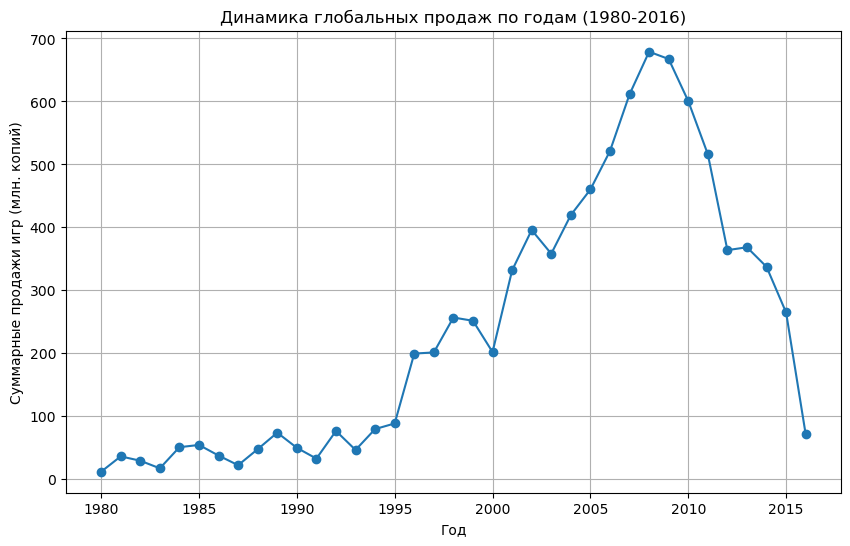

In [62]:
# построим динамику продаж за 1980 - 2016 (линейный график)
# sales_by_year
plt.figure(figsize=(10, 6))
plt.plot(sales_by_year.index, sales_by_year.values, marker='o')
plt.title("Динамика глобальных продаж по годам (1980-2016)")
plt.xlabel("Год")
plt.ylabel("Суммарные продажи игр (млн. копий)")
plt.grid(True)
plt.show()

In [63]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
Index: 16327 entries, 0 to 16597
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Rank          16327 non-null  int64  
 1   Name          16327 non-null  object 
 2   Platform      16327 non-null  object 
 3   Year          16327 non-null  int64  
 4   Genre         16327 non-null  object 
 5   Publisher     16327 non-null  object 
 6   NA_Sales      16327 non-null  float64
 7   EU_Sales      16327 non-null  float64
 8   JP_Sales      16327 non-null  float64
 9   Other_Sales   16327 non-null  float64
 10  Global_Sales  16327 non-null  float64
dtypes: float64(5), int64(2), object(4)
memory usage: 1.5+ MB
None


In [64]:
# Корреляционная матрица продаж в разных регионах
# NA_Sales EU_Sales JP_Sales Other_Sales
corr_matrix = df[['NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales']].corr()
corr_matrix

,NA_Sales,EU_Sales,JP_Sales,Other_Sales
NA_Sales,1.000000,0.768936,0.451285,0.634508
EU_Sales,0.768936,1.000000,0.436414,0.726266
JP_Sales,0.451285,0.436414,1.000000,0.290653
Other_Sales,0.634508,0.726266,0.290653,1.000000


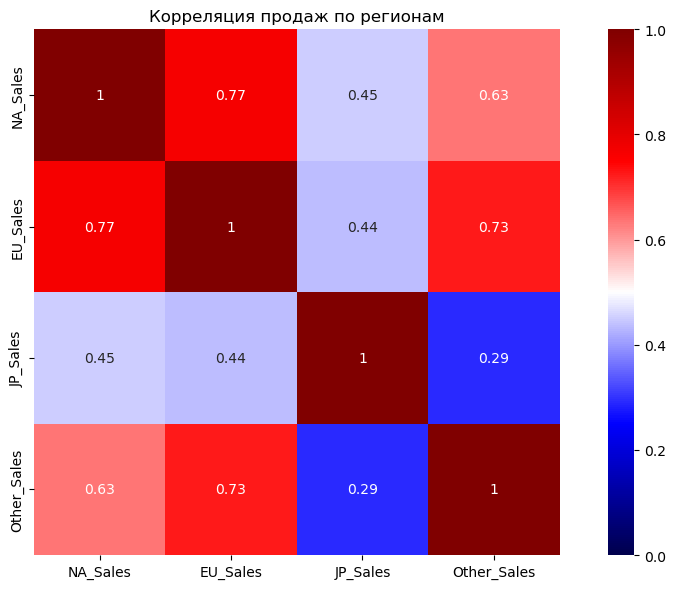

In [65]:
# построим heatmap(тепловую карту) корреляций между продажами по регионам
plt.figure(figsize=(10, 6))
sns.heatmap(corr_matrix, annot=True, cmap='seismic', vmin=0, vmax=1, square=True)
plt.title("Корреляция продаж по регионам")
plt.xticks(rotation=45)
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [66]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
Index: 16327 entries, 0 to 16597
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Rank          16327 non-null  int64  
 1   Name          16327 non-null  object 
 2   Platform      16327 non-null  object 
 3   Year          16327 non-null  int64  
 4   Genre         16327 non-null  object 
 5   Publisher     16327 non-null  object 
 6   NA_Sales      16327 non-null  float64
 7   EU_Sales      16327 non-null  float64
 8   JP_Sales      16327 non-null  float64
 9   Other_Sales   16327 non-null  float64
 10  Global_Sales  16327 non-null  float64
dtypes: float64(5), int64(2), object(4)
memory usage: 1.5+ MB
None


In [67]:
# посчитаем сумму глобальных продаж по издателям и выберем топ-10
# Publisher Global_Sales
publisher_sales= df.groupby('Publisher')['Global_Sales'].sum().sort_values(ascending=False)
top10_pub = publisher_sales.head(10)
top10_pub

Publisher
Nintendo                        1784.43
Electronic Arts                 1093.39
Activision                       721.41
Sony Computer Entertainment      607.28
Ubisoft                          473.54
Take-Two Interactive             399.30
THQ                              340.44
Konami Digital Entertainment     278.56
Sega                             270.70
Namco Bandai Games               253.65
Name: Global_Sales, dtype: float64

/tmp/ipykernel_173/3900053199.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top10_pub.values, y=top10_pub.index, orient='h', palette='muted')


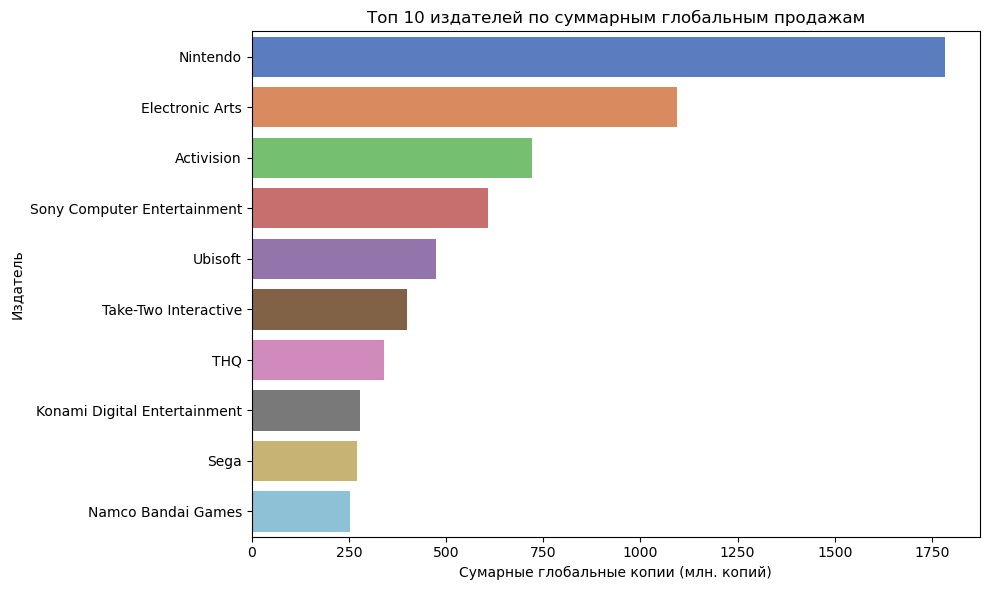

In [68]:
# построим горизонтальную столбчатую диаграмму для топ-10 издателей
plt.figure(figsize=(10, 6))
sns.barplot(x=top10_pub.values, y=top10_pub.index, orient='h', palette='muted')
plt.title("Топ 10 издателей по суммарным глобальным продажам")
plt.xlabel("Cумарные глобальные копии (млн. копий)")
plt.ylabel("Издатель")
plt.tight_layout()
plt.show()

/tmp/ipykernel_173/891191840.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=genre_counts.index,
/tmp/ipykernel_173/891191840.py:45: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top10_pub.values, y=top10_pub.index, orient='h', palette='muted')


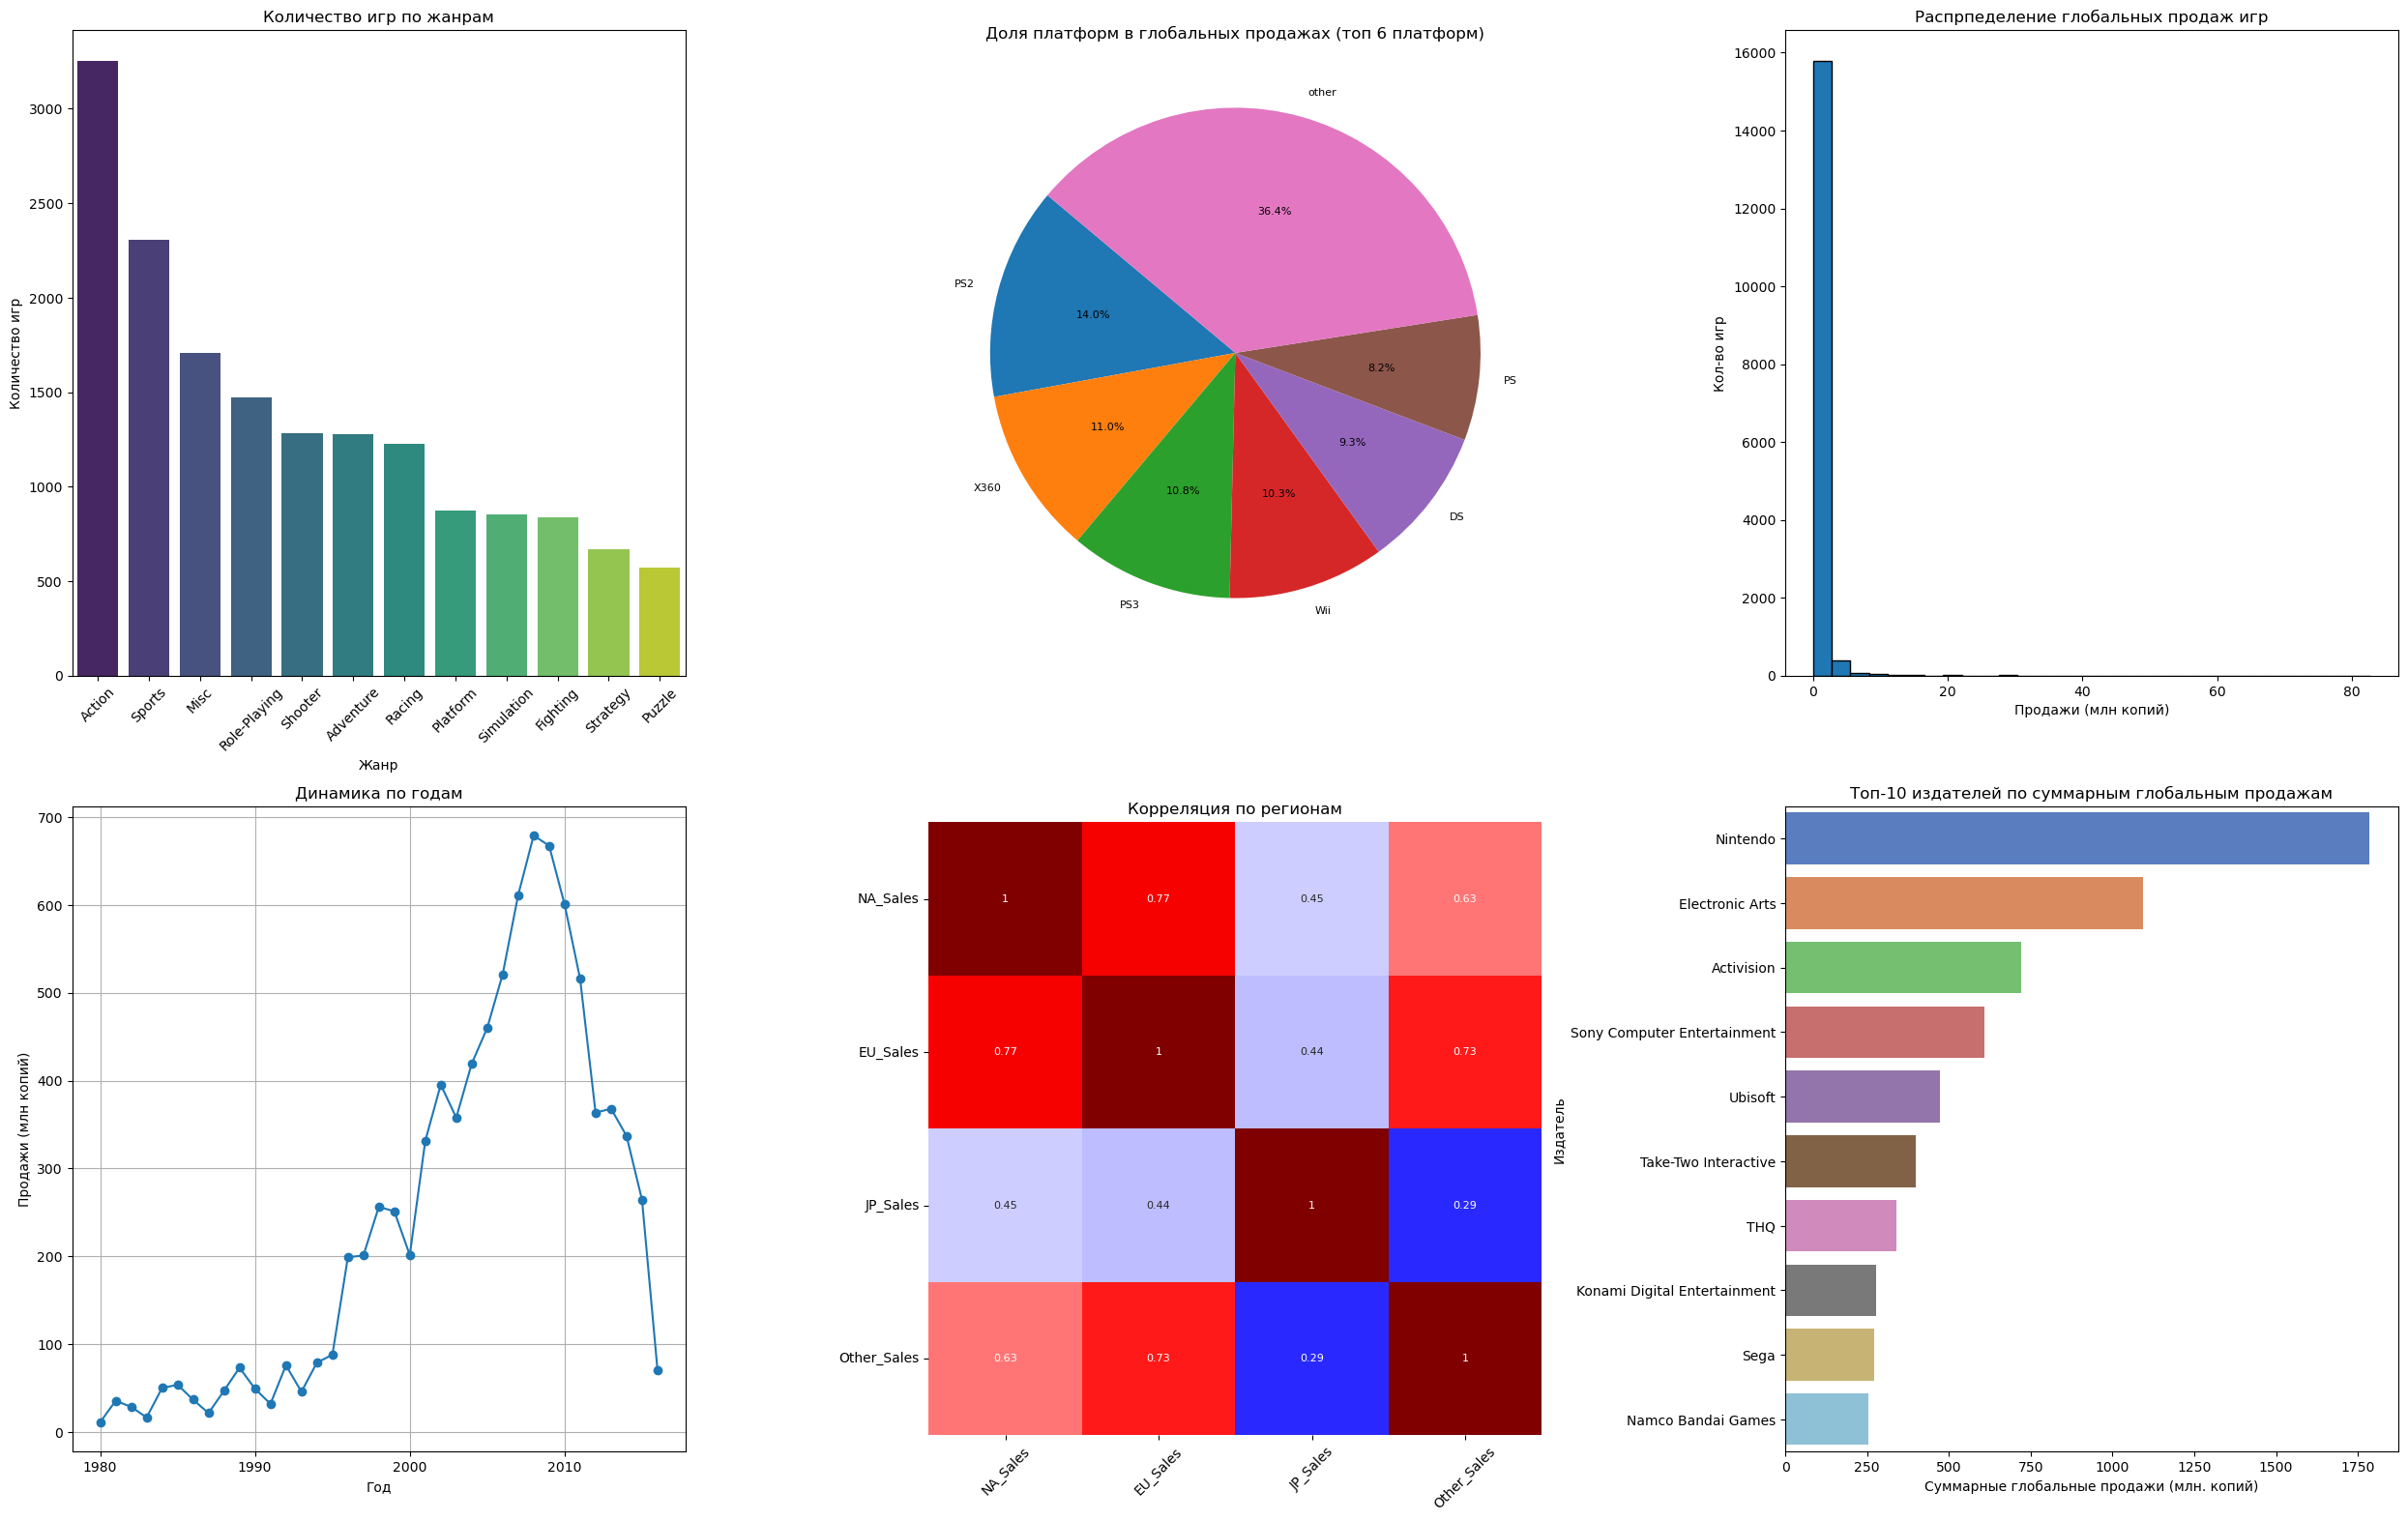

In [71]:
# итоговый дашборд
# 2 ряда по 3 колонки

fig, axes = plt.subplots(2, 3, figsize=(25, 16))


# количество игр по жанрам
sns.barplot(x=genre_counts.index, 
            y=genre_counts.values, 
            ax=axes[0, 0], palette='viridis')
axes[0, 0].set_title("Количество игр по жанрам")
axes[0, 0].set_xlabel('Жанр')
axes[0, 0].set_ylabel('Количество игр')
axes[0, 0].tick_params(axis='x', rotation=45)

# Доля платформ в глобальных продажах (топ 6 платформ)
axes[0, 1].pie(sizes, labels=labels, autopct='%1.1f%%', 
               startangle=140, textprops={'fontsize': 8})
axes[0, 1].set_title('Доля платформ в глобальных продажах (топ 6 платформ)')

# Распределение глобальных продаж
axes[0, 2].hist(df['Global_Sales'], bins=30, edgecolor='black')
axes[0, 2].set_title("Распрпеделение глобальных продаж игр")
axes[0, 2].set_xlabel('Продажи (млн копий)')
axes[0, 2].set_ylabel('Кол-во игр')

# Динамика продаж по годам 
axes[1, 0].plot(sales_by_year.index, sales_by_year.values, marker='o')
axes[1, 0].set_title('Динамика по годам')
axes[1, 0].set_xlabel('Год')
axes[1, 0].set_ylabel('Продажи (млн копий)')
axes[1, 0].grid(True)
axes[1, 0].set_xticks(range(1980, 2017, 10))

# Построим тепловую карту (heatmap) корреляций между продажами по регионгам
sns.heatmap(corr_matrix, annot=True, cmap='seismic', vmin=0, vmax=1, 
            square=True, ax=axes[1, 1], cbar=False, annot_kws={"size": 8})
axes[1, 1].set_title('Корреляция по регионам')
axes[1, 1].set_xticklabels(axes[1, 1].get_xticklabels(), rotation=45)
axes[1, 1].set_yticklabels(axes[1, 1].get_yticklabels(), rotation=0)



# построим горизонтальную столбчатую диаграму для топ-10 издателей
sns.barplot(x=top10_pub.values, y=top10_pub.index, orient='h', palette='muted')
axes[1, 2].set_title("Топ-10 издателей по суммарным глобальным продажам")
axes[1, 2].set_xlabel("Суммарные глобальные продажи (млн. копий)")
axes[1, 2].set_ylabel('Издатель')



plt.tight_layout()

plt.savefig("dashboard.png", dpi=300, bbox_inches='tight')

plt.show()